# **Assignment Week 3 - Time Series Forecasting**

Choose one of the dataset proposed, and fill the following boxes with your code. Then run your code and submit the file with your code and the output. 

**Import the Libraries**

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing, Holt
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima
from statsmodels.tsa.forecasting.theta import ThetaModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, train_test_split

**Load the Dataset**

If your dataset is a .csv file, use the pandas function *read_csv*, if it's a .xlsx file, use *read_excel*

In [71]:
#load the dataset
data = pd.read_csv('Monthly_Google_Search_Iceland_Reykjavik.csv')

**Plot the time series**

Do not split the dataset yet, just plot the time series

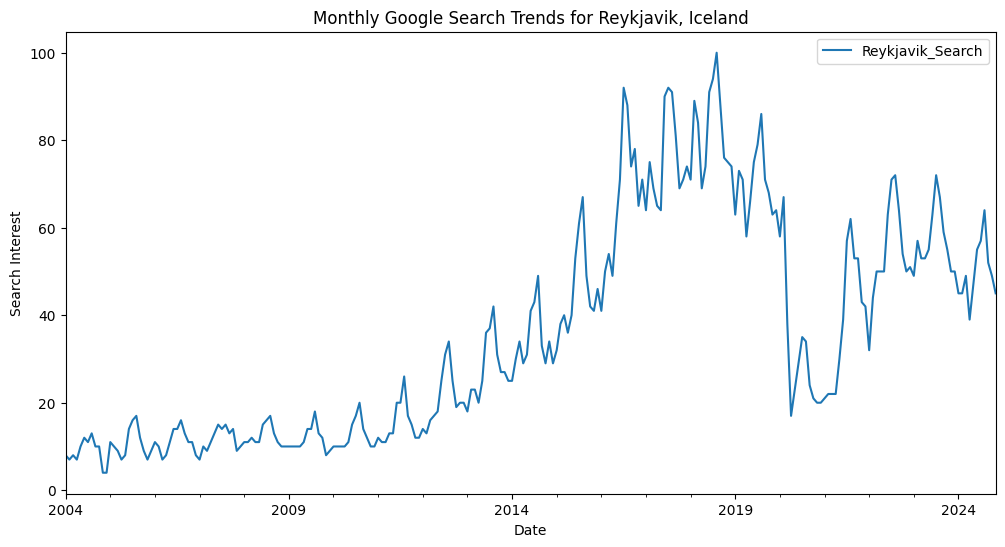

In [72]:
#plot the time series
data['Month'] = pd.to_datetime(data['Month'])
data.set_index('Month', inplace=True)
data.plot(figsize=(12,6))
plt.title('Monthly Google Search Trends for Reykjavik, Iceland')
plt.xlabel('Date')
plt.ylabel('Search Interest')
plt.show()

**Decompose your time series**

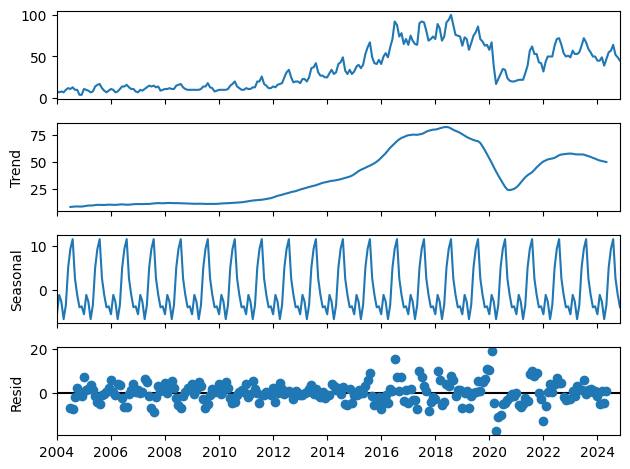

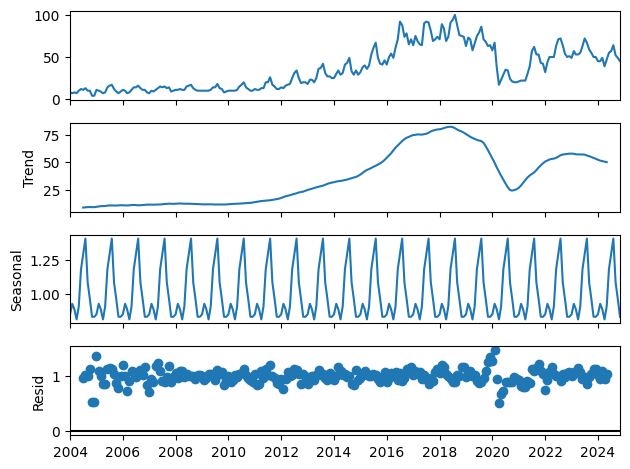

In [73]:
#decompose the time series 
decomposition_add = seasonal_decompose(data, model='additive', period=12)
decomposition_mul = seasonal_decompose(data, model='multiplicative', period=12)

#plot the decompositions
decomposition_add.plot()
decomposition_mul.plot()
plt.show()

From the results you obtained, could you say if the dataset is multiplicative or additive?

it's multiplicative because seasonal variations because the residuals are more stable in the multiplicative decomposition. And the seasonal patterns increase with the trend.

**Check if the data is stationary**

In [74]:
result = adfuller(data['Reykjavik_Search'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])

ADF Statistic: -2.0586041234922616
p-value: 0.2614823975967986


Is the data stationary? why?

no, the data is not stationary because the p-value is greater than 0.05

If the data is not stationary, fix it here:

In [75]:
data_diff = data.diff().dropna()
data_diff_seasonal= data_diff.diff(12).dropna()

#check again stationarity
result_diff = adfuller(data_diff_seasonal['Reykjavik_Search'])
print('ADF Statistic:', result_diff[0])
print('p-value:', result_diff[1])

ADF Statistic: -6.0737215377490985
p-value: 1.1346792522230047e-07


Is the data stationary now? If not, fix it here:

In [76]:
# leave blank if the data is stationary

**Plot autocorrelation (ACF) and partial autocorrelation (PACF)** 

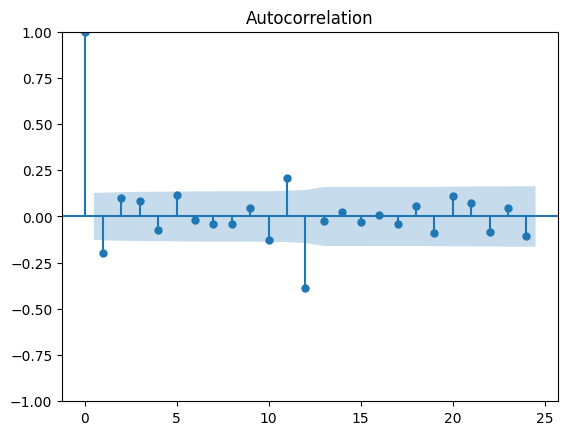

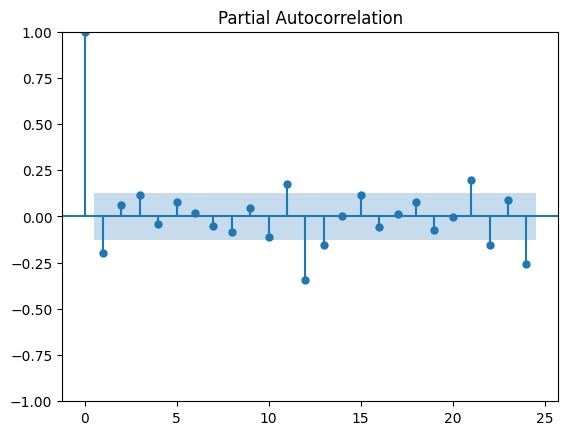

In [77]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(data_diff_seasonal['Reykjavik_Search'])
plot_pacf(data_diff_seasonal['Reykjavik_Search'])
plt.show()

Are there significant spikes? Which lags are significant?

there are not significant spikes because now we have stationary data according to the ADF test

**(Bonus): Find Structural breaks**

The code has to be in R, you can run it on R studio and paste it here.

*#paste code here*


install.packages("tidyverse")
install.packages("ggplot2")
install.packages("lubridate")
install.packages("forecast")
install.packages("xts")
install.packages("strucchange")
install.packages("CPAT")
library(tidyverse)
library(ggplot2)
library(lubridate)
library(forecast)
library(tseries)
library(xts)
library(strucchange)
library(CPAT)



#Data Import 
data <- read_csv("Monthly_Google_Search_Iceland_Reykjavik.csv")

head(data)


Search <- ts(data$`Reykjavik_Search`, start = c(2004, 1), frequency = 12)

# Verify the time series object
print(Search)

bp.Search <- breakpoints(Search ~ 1, h = 0.1, breaks = 8)

plot(bp.Search)

num_breaks <- which.min(bp.Search$RSS()) # This finds the optimal number of breaks

plot(Search)
# Plot the fitted segmented model for the selected number of breaks
lines(fitted(bp.Search, breaks = num_breaks), lwd = 3, col = 'blue')


ci_Search <- confint(bp.Search, breaks = num_breaks)
lines(ci_Search)



print(paste("Optimal number of breaks chosen by BIC/min RSS:", num_breaks))


print(ci_Search)



Are there any structural breaks? How many? When?

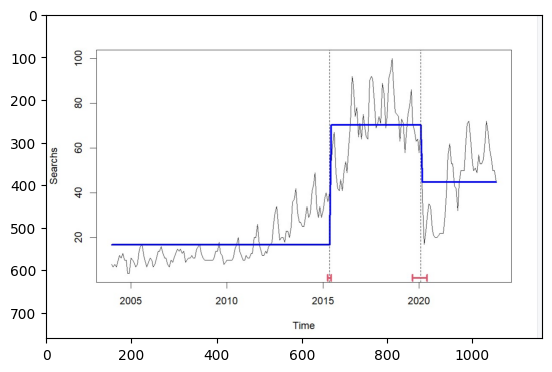

In [95]:
#print results from R code
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

img = mpimg.imread('image_2.jpeg')

plt.imshow(img)

**Preprocessing**

**1. Remove trends and seasonality**

In [78]:
#detrend
data_diff = data.diff().dropna()

#deseasonalize
decomposition=seasonal_decompose(data, model='multiplicative', period=12)
data_deseasonalized = data_diff['Reykjavik_Search'] / decomposition.seasonal
data_deseasonalized = data_deseasonalized.dropna()

**2. Smooth out the outliers**

In [79]:
window_size= 3
data_smoothed= data_deseasonalized.rolling(window=window_size, center=True).mean()
data_smoothed= data_smoothed.dropna()

**3. Plot the results**

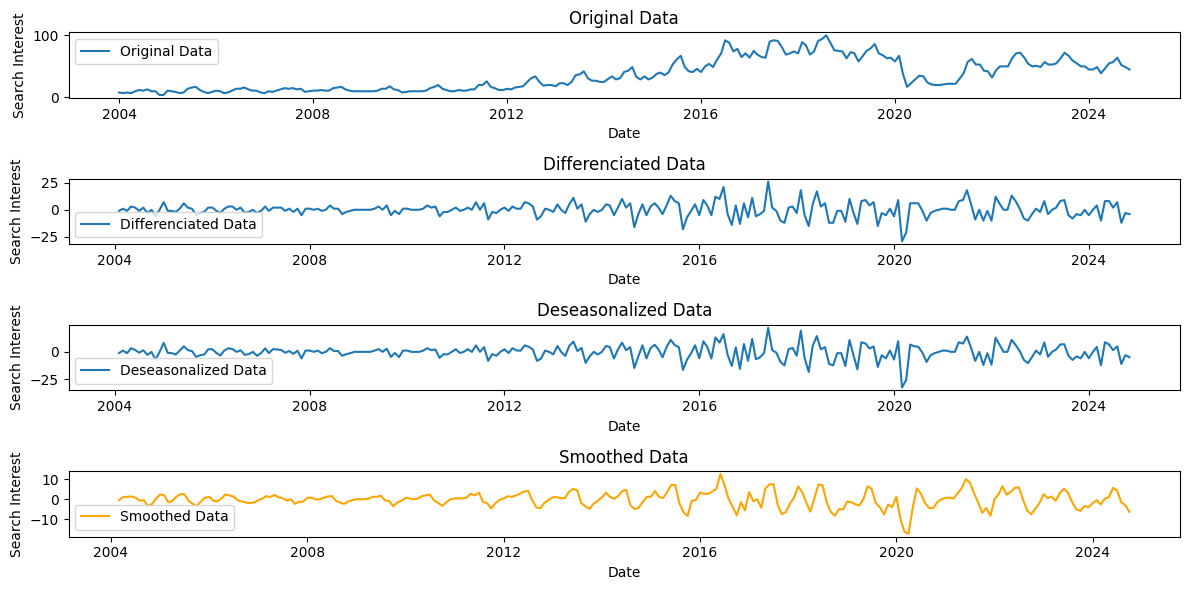

In [80]:
plt.figure(figsize=(12,6))


#plot original data
plt.subplot(4,1,1)
plt.plot(data, label='Original Data')
plt.title('Original Data')
plt.xlabel('Date')
plt.ylabel('Search Interest')
plt.legend()
#plot differenciated data
plt.subplot(4,1,2)
plt.plot(data_diff, label='Differenciated Data')
plt.title('Differenciated Data')
plt.xlabel('Date')
plt.ylabel('Search Interest')
plt.legend()
#plot deseasonalized data
plt.subplot(4,1,3)
plt.plot(data_deseasonalized, label='Deseasonalized Data')
plt.title('Deseasonalized Data')
plt.xlabel('Date')
plt.ylabel('Search Interest')
plt.legend()
#plot smoothed data
plt.subplot(4,1,4)
plt.plot(data_smoothed, color='orange', label='Smoothed Data')
plt.title('Smoothed Data')  
plt.xlabel('Date')
plt.ylabel('Search Interest')
plt.legend()
plt.tight_layout()
plt.show()  


Is there a lot of difference? What can you say about the original data seeing the difference with the preprocessed one?

yes, the preprocessed data is more stable and easier to analyze because the trends and seasonality have been removed, allowing us to focus on the underlying patterns and variations in the data.

**Split the data in train and test** and plot the result

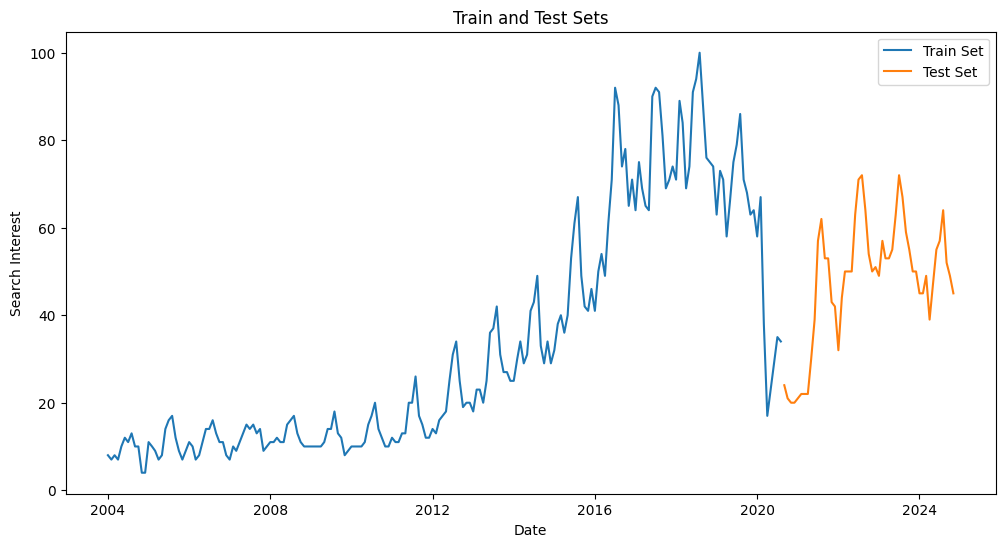

In [81]:
#split the data in train and test sets
train_size = int(len(data) * 0.8)
train, test = data[:train_size], data[train_size:]

#plot the series divided in train and test sets
plt.figure(figsize=(12,6))
plt.plot(train, label='Train Set')
plt.plot(test, label='Test Set')
plt.title('Train and Test Sets')
plt.xlabel('Date')
plt.ylabel('Search Interest')
plt.legend()
plt.show()

Experiment with different train-test splits/forecasting horizons (1 for 1 point, 3 for the possibility of having 3 points) to determine which prediction horizon yields the best results for various models. The primary aim is to observe and compare how each model performs under varying conditions and to identify scenarios where one model outperforms others.

Task: Use the models presented in the *TimeSeriesNotebook.ipynb* to **forecast** your time series data. Then, **evaluate** the performance of each model both through **manual validation** and **cross-validation (bonus)**.

Examples (train,test) : (0.8 * data,0.2 * data) ; (0.7 * data,0.3 * data); (0.6 * data, 0.4 * data); but also fixed numbers like (x, y) (for a dataset of x+y length)

**Forecasting: Choose between 3-5 models presented**

In [82]:
def plot_forecast(forecast, model_name):
    plt.figure(figsize=(10, 6))
    plt.plot(data, label="Original Data")
    plt.plot(train, label="Train Data", color="blue")
    plt.plot(test, label="Test Data", color="green")
    plt.plot(forecast, label=f"{model_name} Forecast", color="red")
    plt.fill_between(forecast.index, forecast - 1.96 * forecast.std(), forecast + 1.96 * forecast.std(), color='red', alpha=0.2)
    plt.title(f"{model_name} Forecast with Confidence Intervals")
    plt.legend()
    plt.show()

In [83]:
# Model 1 : seasonal naive model
def seasonal_naive_model(train, test):
    seasonal_period= 12

    seasonal_naive_values= (train['Reykjavik_Search'].iloc[-seasonal_period:].values.tolist()
                        * (len(test) // seasonal_period + 1))[:len(test)]

    seasonal_naive_forecast = pd.Series(seasonal_naive_values, index=test.index)

    plot_forecast(seasonal_naive_forecast, 'Seasonal Naive Model')
    
    return seasonal_naive_forecast

In [84]:
# Model 2 : Moving average Model
def moving_average_model(train, test):  
    window_size= 12
    moving_average_forecast= test.copy()
    moving_average_forecast['Reykjavik_Search']= train['Reykjavik_Search'].rolling(window=window_size).mean().iloc[-1]

    plot_forecast(moving_average_forecast['Reykjavik_Search'], 'Moving Average Model')

    return moving_average_forecast

In [85]:
# Model 3 : AUTO-ARIMA Model
def auto_arima_model(train, test):
    arima_model = auto_arima(train['Reykjavik_Search'], seasonal=True, m=12, trace=True,
                         error_action='ignore', suppress_warnings=True)
    arima_forecast = arima_model.predict(n_periods=len(test))
    arima_forecast = pd.Series(arima_forecast, index=test.index)
    plot_forecast(arima_forecast, 'ARIMA Model')
    return arima_forecast

Results for train-test split at 70%-30%:


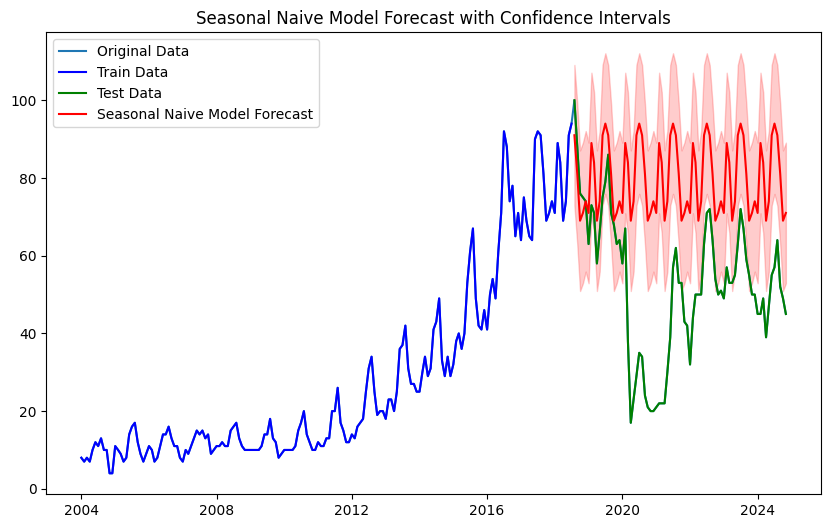

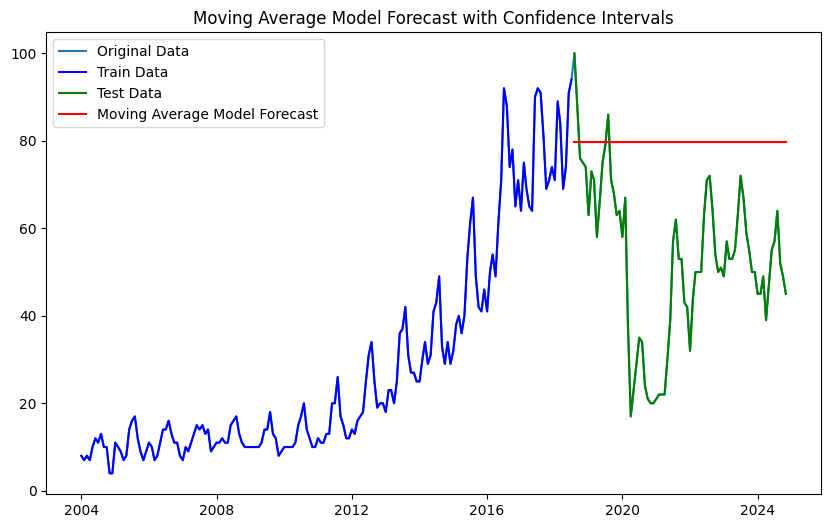

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,1,1)[12]             : AIC=884.574, Time=0.54 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=952.695, Time=0.02 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=890.458, Time=0.09 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=885.275, Time=0.14 sec
 ARIMA(2,1,2)(0,1,1)[12]             : AIC=882.575, Time=0.47 sec
 ARIMA(2,1,2)(0,1,0)[12]             : AIC=894.955, Time=0.23 sec
 ARIMA(2,1,2)(0,1,2)[12]             : AIC=884.574, Time=1.53 sec
 ARIMA(2,1,2)(1,1,0)[12]             : AIC=885.457, Time=0.37 sec
 ARIMA(2,1,2)(1,1,2)[12]             : AIC=886.218, Time=2.07 sec
 ARIMA(1,1,2)(0,1,1)[12]             : AIC=887.472, Time=0.31 sec
 ARIMA(2,1,1)(0,1,1)[12]             : AIC=880.796, Time=0.28 sec
 ARIMA(2,1,1)(0,1,0)[12]             : AIC=893.461, Time=0.12 sec
 ARIMA(2,1,1)(1,1,1)[12]             : AIC=882.786, Time=0.45 sec
 ARIMA(2,1,1)(0,1,2)[12]             : AIC=882.775, Time=1.18 sec
 ARIMA(2,1,1)(1,1,0)[12]         

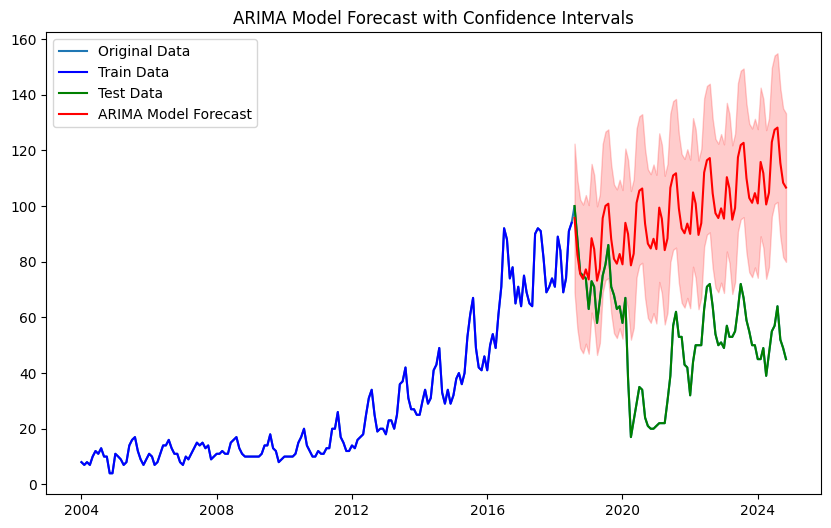

Results for train-test split at 80%-19%:


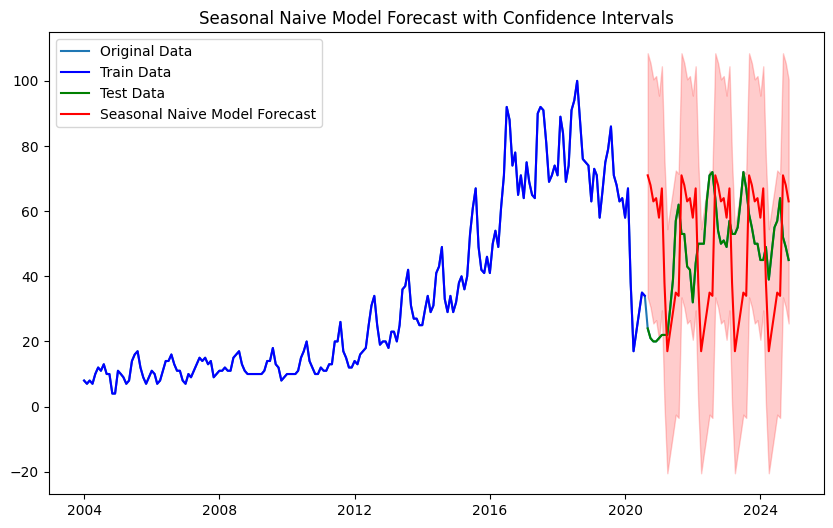

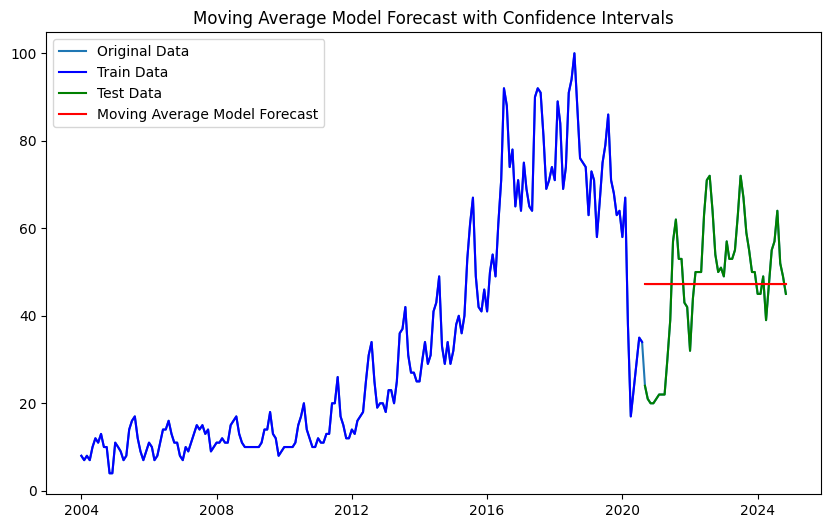

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=1.11 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1317.765, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=1184.825, Time=0.17 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1247.333, Time=0.28 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1315.843, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=1319.135, Time=0.05 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=1176.687, Time=0.33 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=1175.292, Time=0.86 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=1173.323, Time=0.30 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=1247.611, Time=0.23 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=1175.249, Time=0.51 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=1227.294, Time=0.46 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=1174.880, Time=0.82 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=1181.067, Time=0.24 sec
 ARIMA(2,1,0)(1,0,1)[12]

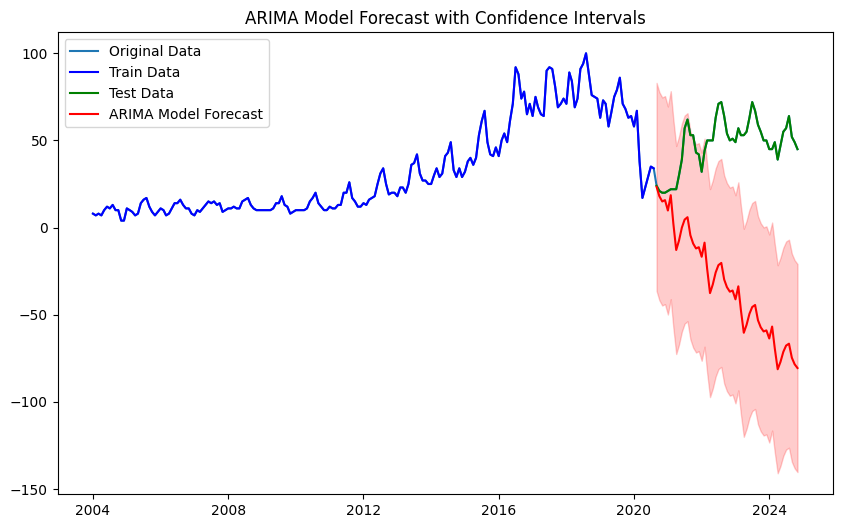

Results for train-test split at 90%-9%:


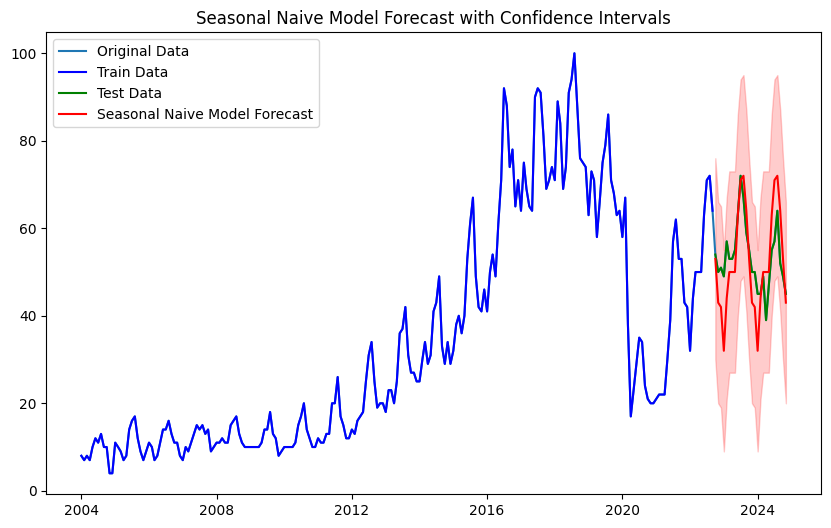

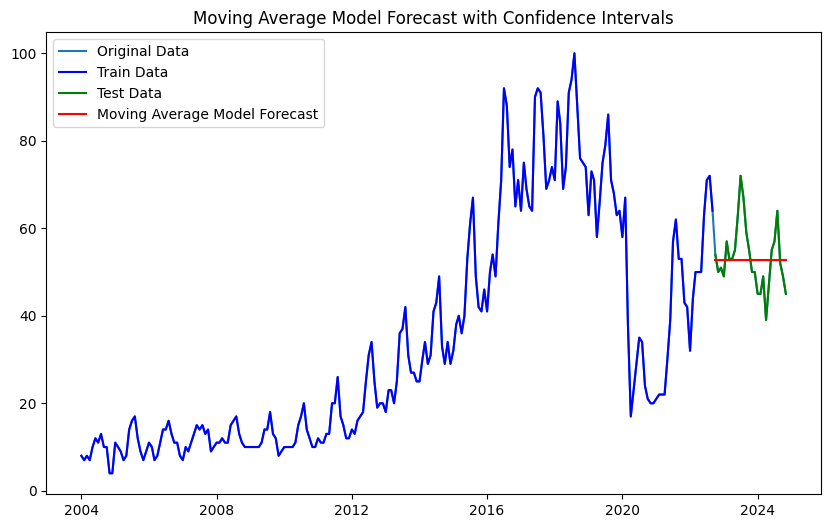

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=1359.914, Time=0.99 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1489.154, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=1378.476, Time=0.16 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1422.735, Time=0.16 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1487.469, Time=0.02 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=1403.119, Time=0.92 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=1384.997, Time=0.63 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=1361.615, Time=2.27 sec
 ARIMA(2,1,2)(1,0,2)[12] intercept   : AIC=1361.517, Time=2.01 sec
 ARIMA(2,1,2)(0,0,0)[12] intercept   : AIC=inf, Time=0.40 sec
 ARIMA(2,1,2)(0,0,2)[12] intercept   : AIC=1392.265, Time=2.19 sec
 ARIMA(2,1,2)(2,0,0)[12] intercept   : AIC=1372.350, Time=1.46 sec
 ARIMA(2,1,2)(2,0,2)[12] intercept   : AIC=1360.833, Time=2.63 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=1358.555, Time=0.81 sec
 ARIMA(1,1,2)(0,0,1)[12]

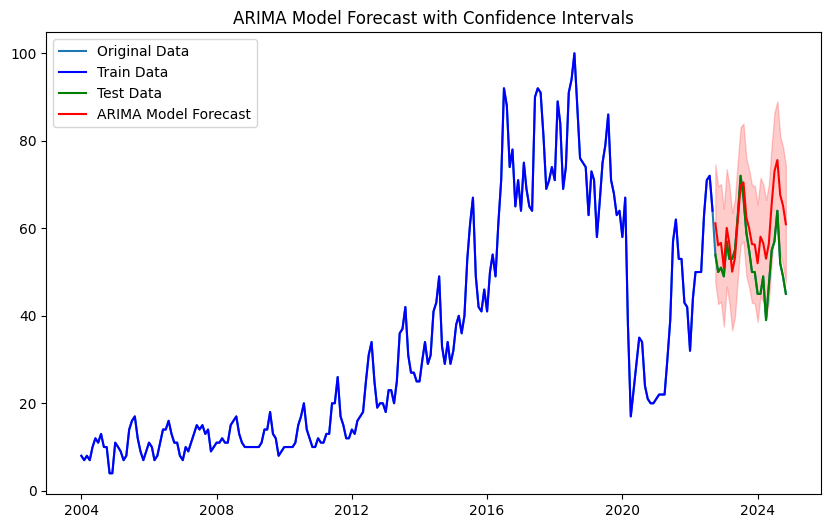

In [86]:
#compute and plot the results of the models results with 3 different splits
splits = [0.7, 0.8, 0.9]
seasonal_naive_results = []
moving_average_results = []
auto_arima_results = []
test_sets = []  # Store test sets for each split

for split in splits:
    train_size = int(len(data) * split)
    train, test = data[:train_size], data[train_size:]
    test_sets.append(test)  # Save the test set
    
    print(f"Results for train-test split at {int(split*100)}%-{int((1-split)*100)}%:")
    
    seasonal_naive_results.append(seasonal_naive_model(train, test))
    moving_average_results.append(moving_average_model(train, test))
    auto_arima_results.append(auto_arima_model(train, test))

**Evaluation**

Chose one of the errors used for the evaluation explained in class and use it to compare the models.

In [87]:
# Manual Evaluation
final_results=[]
for i, split in enumerate(splits):
    test= data[ int(len(data) * split) : ]  
    test = test_sets[i]  # Use the correct test set for each split
    results = {
        "Model": ["Seasonal Naive", "Moving Average", "Auto-ARIMA"],
        "MSE": [
            mean_squared_error(test['Reykjavik_Search'], seasonal_naive_results[i]),
            mean_squared_error(test['Reykjavik_Search'], moving_average_results[i]),    
            mean_squared_error(test['Reykjavik_Search'], auto_arima_results[i])
        ]
    }
    
    print(f"\nResults for {int(split*100)}-{int((1-split)*100)} split:")
    results_df = pd.DataFrame(results)
    print(f"Best model: {results_df.loc[results_df['MSE'].idxmin(), 'Model']}"+" with MSE:"+str(results_df['MSE'].min()))
    final_results.append(results_df)


Results for 70-30 split:
Best model: Seasonal Naive with MSE:1056.5657894736842

Results for 80-19 split:
Best model: Moving Average with MSE:203.54289215686273

Results for 90-9 split:
Best model: Moving Average with MSE:52.540598290598275


In [88]:
final_results[0]

,Model,MSE
0,Seasonal Naive,1056.565789
1,Moving Average,1076.001462
2,Auto-ARIMA,2519.135299


In [89]:
final_results[1]

,Model,MSE
0,Seasonal Naive,673.176471
1,Moving Average,203.542892
2,Auto-ARIMA,7989.961142


In [90]:
final_results[2]

,Model,MSE
0,Seasonal Naive,61.115385
1,Moving Average,52.540598
2,Auto-ARIMA,81.652280


Which model is the best? For which forecasting horizon?

the best model in general is moving average because it has the lowest MSE in 2 splits out of 3.


**(Bonus): Cross-Validation**

In [91]:
# Cross-Validation
tscv = TimeSeriesSplit(n_splits=3)

Train indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64], Test indices: [ 65  66  67  68  69  70  71  72  73  74  75  76  77  78  79  80  81  82
  83  84  85  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100
 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118
 119 120 121 122 123 124 125 126]


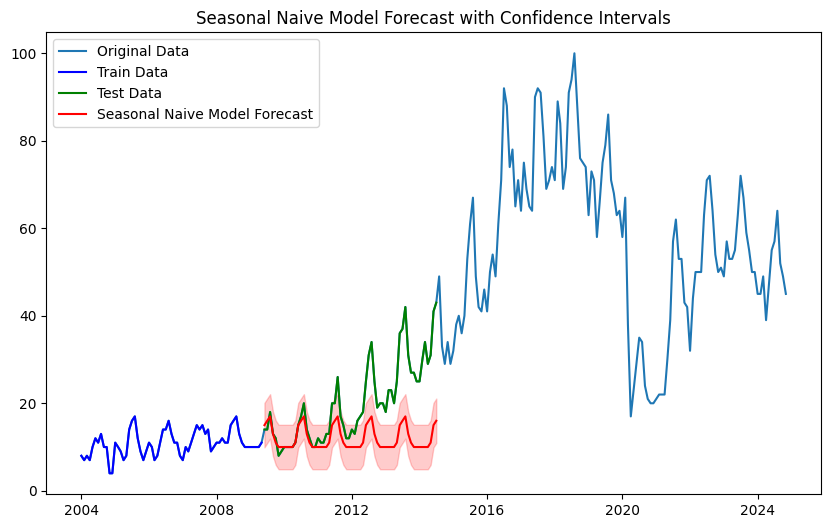

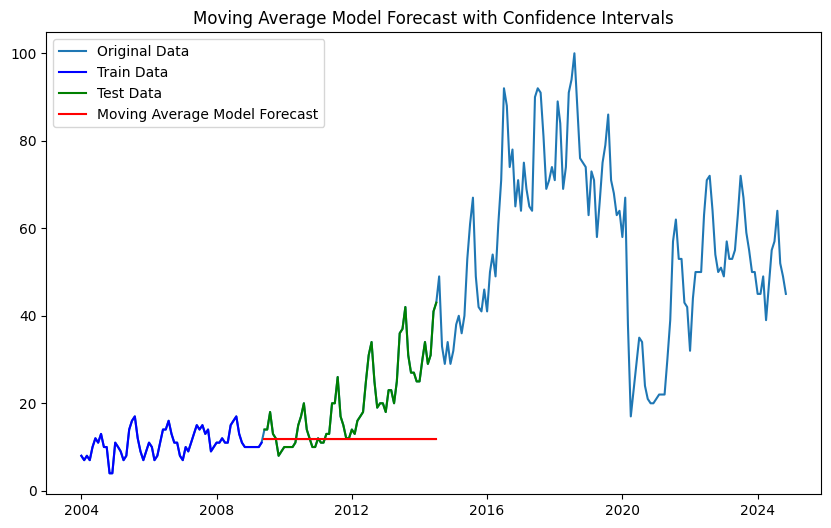

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[12] intercept   : AIC=277.654, Time=0.68 sec
 ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=325.323, Time=0.01 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=276.624, Time=0.13 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : AIC=278.462, Time=0.09 sec
 ARIMA(0,0,0)(0,0,0)[12]             : AIC=500.916, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[12] intercept   : AIC=291.101, Time=0.04 sec
 ARIMA(1,0,0)(2,0,0)[12] intercept   : AIC=276.832, Time=0.24 sec
 ARIMA(1,0,0)(1,0,1)[12] intercept   : AIC=272.941, Time=0.41 sec
 ARIMA(1,0,0)(0,0,1)[12] intercept   : AIC=279.475, Time=0.11 sec
 ARIMA(1,0,0)(2,0,1)[12] intercept   : AIC=inf, Time=0.63 sec
 ARIMA(1,0,0)(1,0,2)[12] intercept   : AIC=274.907, Time=0.69 sec
 ARIMA(1,0,0)(0,0,2)[12] intercept   : AIC=281.456, Time=0.19 sec
 ARIMA(1,0,0)(2,0,2)[12] intercept   : AIC=inf, Time=0.82 sec
 ARIMA(0,0,0)(1,0,1)[12] intercept   : AIC=292.697, Time=0.36 sec
 ARIMA(2,0,0)(1,0,1)[12] intercept   : AI

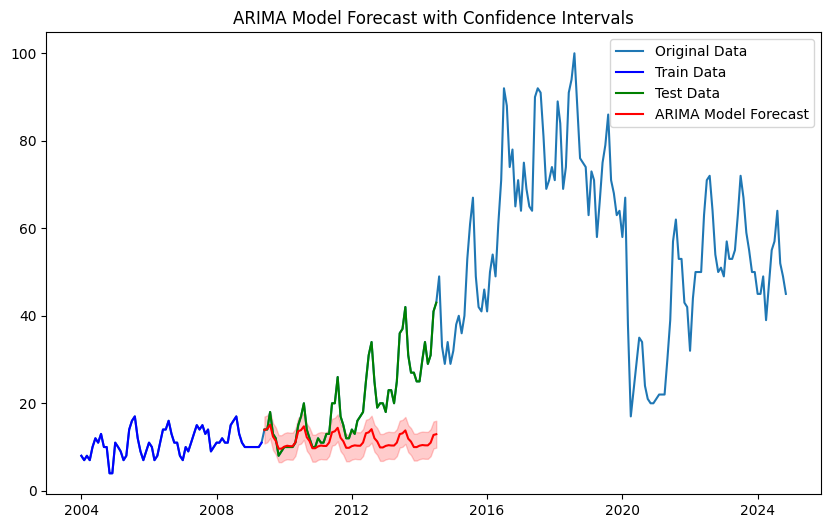

Train indices: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126], Test indices: [127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162
 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180
 181 182 183 184 185 186 187 188]


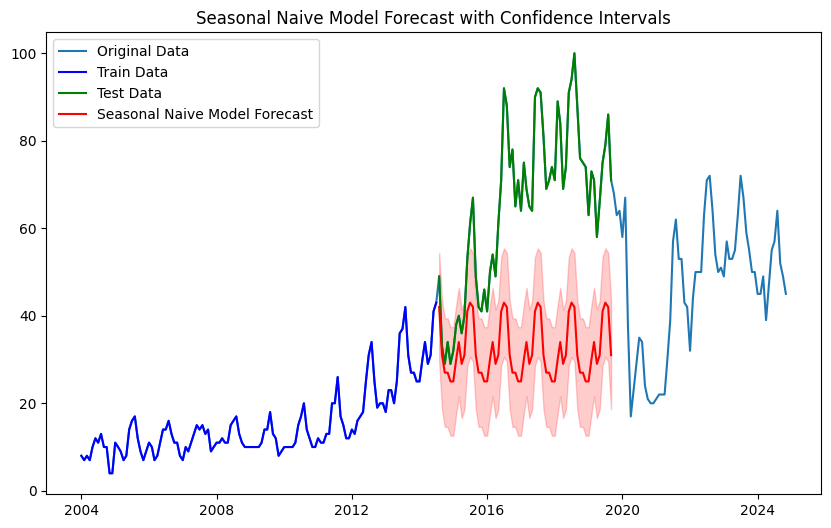

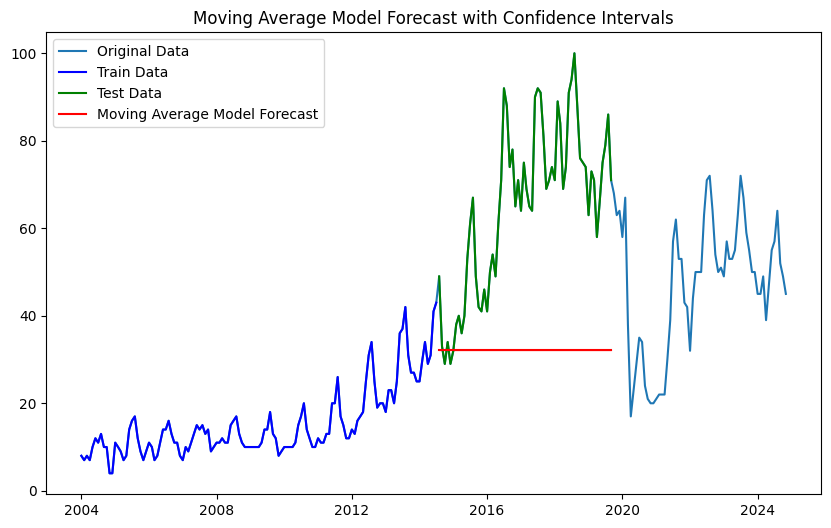

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,1,1)[12]             : AIC=485.945, Time=0.34 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=526.567, Time=0.02 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=506.172, Time=0.06 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=489.790, Time=0.10 sec
 ARIMA(2,1,2)(0,1,1)[12]             : AIC=484.644, Time=0.30 sec
 ARIMA(2,1,2)(0,1,0)[12]             : AIC=489.872, Time=0.10 sec
 ARIMA(2,1,2)(0,1,2)[12]             : AIC=485.872, Time=0.68 sec
 ARIMA(2,1,2)(1,1,0)[12]             : AIC=483.945, Time=0.24 sec
 ARIMA(2,1,2)(2,1,0)[12]             : AIC=485.944, Time=0.47 sec
 ARIMA(2,1,2)(2,1,1)[12]             : AIC=487.943, Time=0.65 sec
 ARIMA(1,1,2)(1,1,0)[12]             : AIC=481.461, Time=0.32 sec
 ARIMA(1,1,2)(0,1,0)[12]             : AIC=492.397, Time=0.08 sec
 ARIMA(1,1,2)(2,1,0)[12]             : AIC=483.416, Time=0.72 sec
 ARIMA(1,1,2)(1,1,1)[12]             : AIC=483.422, Time=0.44 sec
 ARIMA(1,1,2)(0,1,1)[12]         

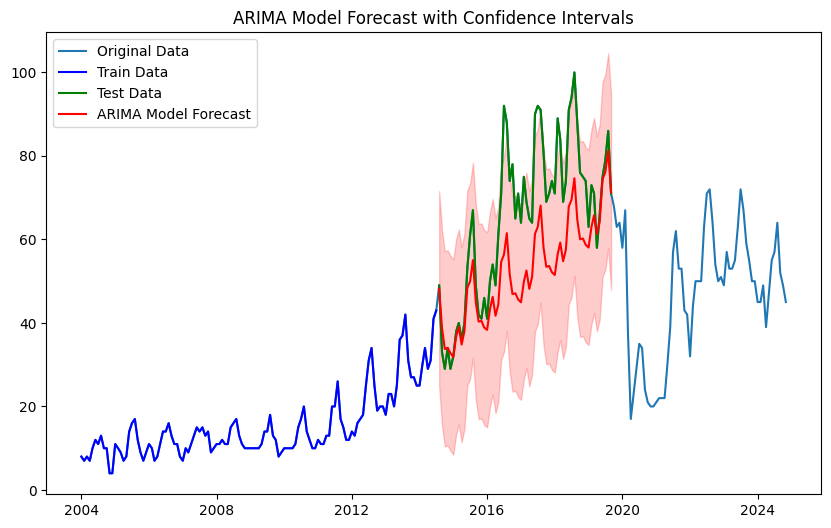

Train indices: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188], Test indices: [189 190 191 192 193 194 195 196 197 198 199 200 201 202 203 204 205 206
 207 208 209 210 211 212 213 214 215 216 217 218 219 220 221 222 223 224
 225 226 227 228 229 230 231 232 233 234 235 236 237 238

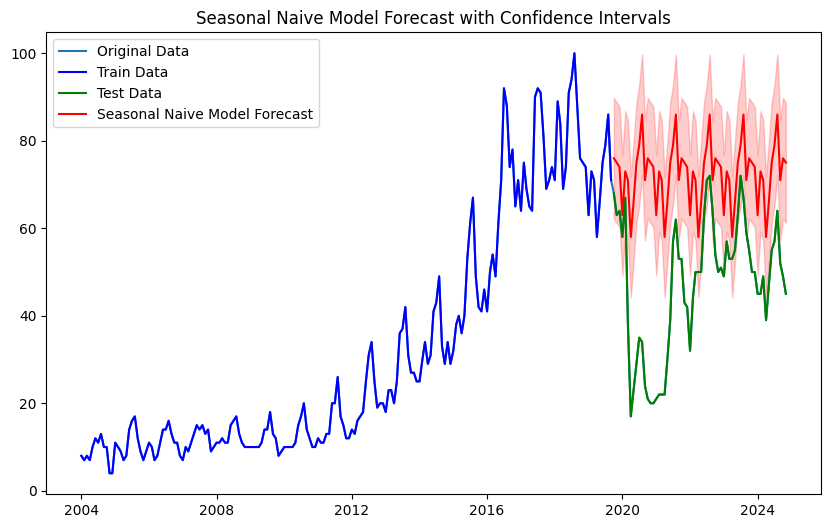

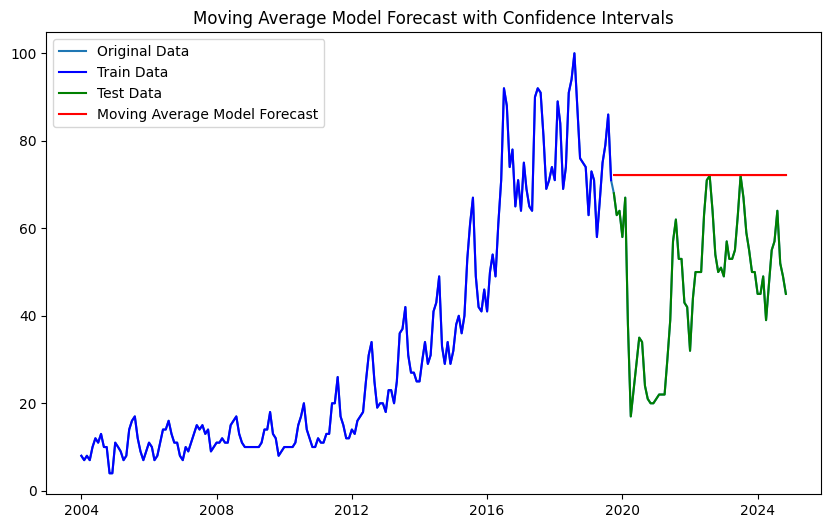

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=1055.346, Time=0.99 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1218.092, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=1064.326, Time=0.13 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1139.663, Time=0.18 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1216.657, Time=0.02 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=1134.355, Time=0.49 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=inf, Time=0.79 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=1057.234, Time=2.07 sec
 ARIMA(2,1,2)(1,0,2)[12] intercept   : AIC=1057.148, Time=2.07 sec
 ARIMA(2,1,2)(0,0,0)[12] intercept   : AIC=1189.876, Time=0.21 sec
 ARIMA(2,1,2)(0,0,2)[12] intercept   : AIC=1110.387, Time=0.90 sec
 ARIMA(2,1,2)(2,0,0)[12] intercept   : AIC=1059.915, Time=1.36 sec
 ARIMA(2,1,2)(2,0,2)[12] intercept   : AIC=1058.348, Time=2.23 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=1054.199, Time=0.81 sec
 ARIMA(1,1,2)(0,0,1)[12]

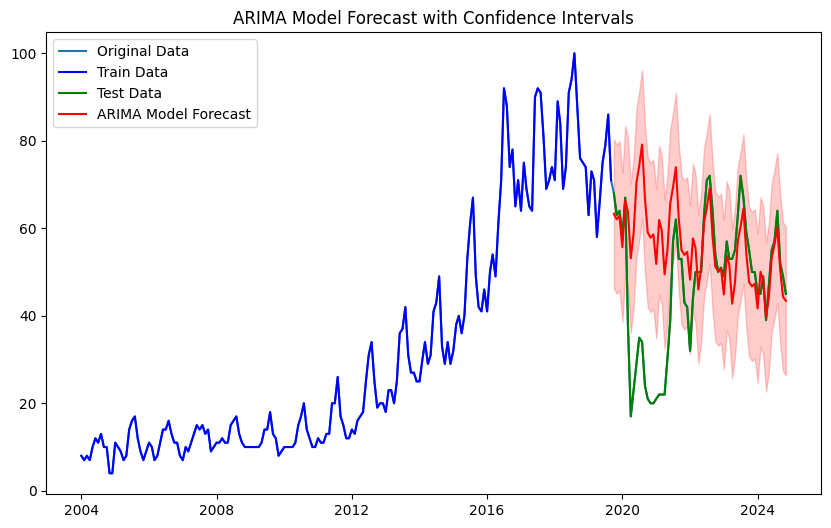

{'seasonal_naive': [129.8709677419355, 1362.983870967742, 824.5483870967741],
 'moving_average': [146.85103046594983, 1446.3537186379924, 853.5141129032259],
 'AUTO_ARIMA': [146.14694478109556, 269.9106308277089, 364.9052400891258]}

In [92]:
results={model:[] for model in ["seasonal_naive","moving_average","AUTO_ARIMA"]}
for train_index, test_index in tscv.split(data):
    train, test = data.iloc[train_index], data.iloc[test_index]
    print(f"Train indices: {train_index}, Test indices: {test_index}")

    #seasonal naive
    seasonal_naive_pred= seasonal_naive_model(train, test)
    results["seasonal_naive"].append(mean_squared_error(test,seasonal_naive_pred))
    #moving average
    moving_average_pred= moving_average_model(train,test)
    results["moving_average"].append(mean_squared_error(test,moving_average_pred))

    #AUTO-ARIMA
    auto_arima_pred=auto_arima_model(train,test)
    results["AUTO_ARIMA"].append(mean_squared_error(test,auto_arima_pred))

results

Is the best model the same as before? For which forecasting horizon?

AUTO-ARIMA is the best model in cross-validation with an average MSE of 260.33, compared to Seasonal Naive (772.46) and Moving Average (815.57). It performs particularly well on the later forecasting horizons (splits 2 and 3) with significantly lower errors, making it the most reliable choice for this time series data.